# Healthy Compounder 候補ファクターの単独評価（core だけで作れる柱）

Notion「インド株：健全な長期成長企業を評価するファクター設計」は、過去の成長率そのものではなく
**成長の質・持続性・ガバナンス**で「健全で長く成長する企業」を評価する、という設計案。根拠は
長期の利益成長に持続性がほとんどないこと（Chan, Karceski & Lakonishok 2003）と、楽観的な長期成長予想の銘柄ほどリターンが低いこと（Bordalo et al. 2019）。

提案の 6 本柱のうち、手元の `core` ファクターとリスクモデルだけで作れる 4 本をここで検証する。
⑤ガバナンス（担保差入・RPT など）はデータが無く、⑥の価格系（52 週高値・オーバーナイト等）は日次ビルダーを作ってから別ノートブックで扱う。
③のうち LTG は 2019 年以降カバー率が 22% 以下に落ちるため使わない。

| スコア | 柱 | 定義（すべて高いほど良い向き） | 根拠 |
| --- | --- | --- | --- |
| `hc_cfoa` | ① | 営業 CF / 総資産（CbOP の代替、§0 参照） | Ball et al. (2016) |
| `hc_cfp` | ① | 営業 CF / 株価 | Hanauer & Lauterbach (2019) |
| `hc_dso` | ① | −(売掛金回転日数の 12 か月変化 − 産業グループ中央値)。金融は対象外 | インドの売掛膨張（提案の工夫） |
| `hc_cash` | ① | 上の 3 本の合成 | |
| `hc_qmj_prof` | ② | GPOA, ROE, ROA, CFOA, GMAR, −ACC（符号は §0 参照） | Asness, Frazzini & Pedersen (2019) |
| `hc_qmj_growth` | ② | 粗利・純利益・営業利益・営業 CF・粗利率の 5 年変化 | 同上 |
| `hc_qmj_safety` | ② | −BETA, −VOLA60, −負債比率, −O-score, Z-score, −ROE の 5 年ばらつき | 同上 |
| `hc_qmj_payout` | ② | −純株式発行, −純負債発行, 5 年純還元/営業利益（参考） | 同上 |
| `hc_qmj` | ② | 収益性 + 成長 + 安全性 | 同上 |
| `hc_sales_stab` | ③ | −売上成長率の過去 5 年の標準偏差 | Chan et al. (2003) |
| `hc_issuance` | ④ | −総合株式発行（CSI）, −純株式発行 | Pontiff & Woodgate (2008), McLean et al. (2009) |
| `hc_all` | 統合 | ①②③④ の柱スコアの等ウェイト合成 | |

作り方は `scripts/build_healthy_compounder.py`: 素材を符号調整して各月ユニバース内で Blom 化 → 柱内で等ウェイト平均 → 再 Blom。
符号は論文どおり事前に決めており、データを見て反転はしていない。
データの定義上の問題が 2 つ見つかったので、§0 で確認したうえで素材を決めた（IC を見て符号を選んだわけではない）。

**規約**: Q5 = スコア最上位。リターンは `drtn`（配当込み）と `srtn`（固有）。累積は drtn が複利、srtn が累和。
税は信託扱い・INR 建て、売買コスト 15/25bp、バーンイン 12 か月。ベンチマークは MSCI India。期間は `comp_ew` と同じ 2008-01 以降。

In [1]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import numpy as np
import pandas as pd

from alphaeval import InputStore, compute_alpha_report, india_tax_schedule, plot_cross_alpha_bars, plot_cumulative, summary_table

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
PILLARS = ["hc_cash", "hc_qmj", "hc_sales_stab", "hc_issuance", "hc_all"]
COMPONENTS = ["hc_cfoa", "hc_cfp", "hc_dso", "hc_qmj_prof", "hc_qmj_growth", "hc_qmj_safety", "hc_qmj_payout"]
SCORES = {"comp_ew": "composite/comp_ew", **{n: f"hc/{n}" for n in PILLARS + COMPONENTS}}
REFERENCE = {"sleeve_a": "composite/sleeve_a", "sleeve_b": "composite/sleeve_b", "sleeve_d": "composite/sleeve_d"}
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
scores = {n: store.alpha(p, START, END).reindex(index=univ.index, columns=univ.columns).where(univ.notna()) for n, p in {**SCORES, **REFERENCE}.items()}

## 0. データ定義の確認

Ball et al. (2016) の CbOP は「営業利益 − 運転資本アクルーアル」。`core` で作ろうとして 2 つの問題が見つかった。

1. **アクルーアルの符号**: `acc_cf`・`acc_bs` は (営業 CF − 純利益)/総資産と強く正に相関する。名前は「アクルーアル」だが、
   中身は「負のアクルーアル」（高いほど利益が現金で裏付けられている）の向き。したがって QMJ の −ACC はそのままの符号で使う。
2. **販管費の分類**: インドの損益計算書は費用を性質別（原材料・人件費・その他）に開示するため、ベンダーの売上総利益と販管費の区分が
   国際基準の機能別と一致しない。人件費が販管費側に入る IT サービスなどが「売上総利益 − 販管費」の下位に集まり、営業利益の代わりにならない。

このため ① のキャッシュ収益性は、区分の影響を受けない営業 CF / 総資産（`ocf_ta`）を CbOP の代替にした。

参考に素材単体の IC も示す。販管費比率は単独で正の IC を持ち、引き算すると符号が逆転する。これは ② の無形資産補正バリュー（Eisfeldt et al. 2022）を支持する材料でもある。

In [2]:
L = lambda c: store.alpha(f"core/{c}", START, END).reindex(index=univ.index, columns=univ.columns).where(univ.notna())
acc_cf, acc_bs, ocf, ni = L("acc_cf"), L("acc_bs"), L("ocf_ta"), L("ni_ta")
cash_backing = ocf - ni
rows = {}
for d in ["2012-06-30", "2016-06-30", "2020-06-30", "2024-06-30"]:
    df = pd.DataFrame({"acc_cf": acc_cf.loc[d], "acc_bs": acc_bs.loc[d], "ocf−ni": cash_backing.loc[d]}).dropna()
    rows[d] = {"銘柄数": len(df), "順位相関(acc_cf, 営業CF−純利益)": df["acc_cf"].corr(df["ocf−ni"], method="spearman"), "順位相関(acc_bs, 営業CF−純利益)": df["acc_bs"].corr(df["ocf−ni"], method="spearman")}
print("1. アクルーアルの符号: (営業 CF − 純利益)/総資産 との順位相関")
display(pd.DataFrame(rows).T.round(2))

gpa, sga, gics = L("gpa_act"), L("sga_ta"), store.alpha("attributes/gics", START, END).reindex(index=univ.index, columns=univ.columns)
op_proxy = (gpa - sga).loc["2019-06-30"].dropna()
q = pd.qcut(op_proxy, 5, labels=[f"Q{i}" for i in range(1, 6)])
sector = (gics.loc["2019-06-30"] // 1_000_000).reindex(op_proxy.index).map({10: "エネルギー", 15: "素材", 20: "資本財", 25: "一般消費財", 30: "生活必需品", 35: "ヘルスケア", 40: "金融", 45: "情報技術", 50: "通信", 55: "公益", 60: "不動産"})
print("2. 「売上総利益 − 販管費」/総資産 の分位別セクター構成（2019-06、銘柄数。Q5 = 最上位）")
display(pd.crosstab(sector, q))

from alphaeval import ic_summary, information_coefficient
from alphaeval.panel import forward_returns
fwd_d = forward_returns(store.returns(RISK_MODEL, "rtn", START, 202607), 1)
cand = {"売上総利益/総資産 (gpa_act)": gpa, "販管費/総資産 (sga_ta)": sga, "(売上総利益 − 販管費)/総資産": gpa - sga, "acc_bs（負のアクルーアル）": acc_bs, "営業 CF/総資産 (ocf_ta)": ocf}
print("3. 素材単体の IC（drtn、翌月、2008-01〜）")
display(pd.DataFrame({k: ic_summary(information_coefficient(v, fwd_d, univ))[["mean", "t_stat"]] for k, v in cand.items()}).T.rename(columns={"mean": "IC", "t_stat": "t"}).round(3))

1. アクルーアルの符号: (営業 CF − 純利益)/総資産 との順位相関


,銘柄数,"順位相関(acc_cf, 営業CF−純利益)","順位相関(acc_bs, 営業CF−純利益)"
2012-06-30,255.0,0.86,0.52
2016-06-30,298.0,0.85,0.72
2020-06-30,248.0,0.84,0.66
2024-06-30,560.0,0.83,0.71


2. 「売上総利益 − 販管費」/総資産 の分位別セクター構成（2019-06、銘柄数。Q5 = 最上位）


2019-06-30 00:00:00,Q1,Q2,Q3,Q4,Q5
2019-06-30 00:00:00,,,,,
エネルギー,0,3,1,6,1
ヘルスケア,6,3,7,12,4
一般消費財,7,7,8,10,21
不動産,0,4,3,1,0
公益,0,6,3,3,2
情報技術,14,1,2,2,1
生活必需品,4,2,6,5,6
素材,18,6,8,9,12
資本財,7,11,13,7,13


3. 素材単体の IC（drtn、翌月、2008-01〜）


,IC,t
売上総利益/総資産 (gpa_act),0.031,2.960
販管費/総資産 (sga_ta),0.033,3.264
(売上総利益 − 販管費)/総資産,-0.014,-2.559
acc_bs（負のアクルーアル）,0.022,4.150
営業 CF/総資産 (ocf_ta),0.036,3.534


## 1. カバレッジ

ユニバース銘柄数に対するスコア保有銘柄の割合。

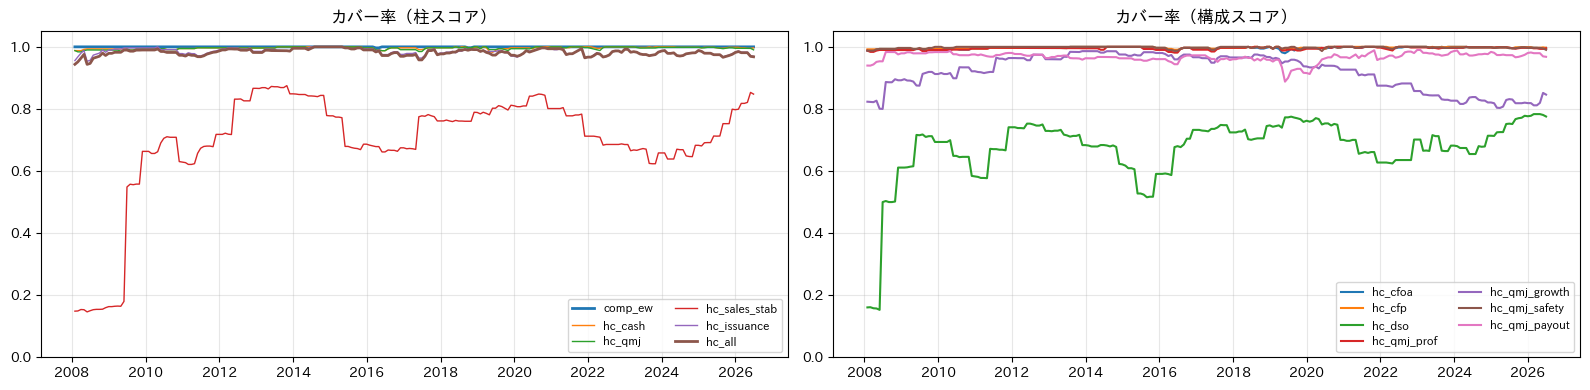

,2008-12-31,2010-12-31,2012-12-31,2014-12-31,2016-12-31,2018-12-31,2020-12-31,2022-12-31,2024-12-31,2026-12-31
comp_ew,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
hc_cash,99.0,99.0,100.0,100.0,99.0,100.0,100.0,100.0,100.0,100.0
hc_qmj,99.0,99.0,100.0,100.0,99.0,100.0,100.0,100.0,100.0,99.0
hc_sales_stab,15.0,68.0,80.0,83.0,67.0,77.0,83.0,69.0,66.0,83.0
hc_issuance,97.0,99.0,99.0,100.0,98.0,99.0,99.0,98.0,98.0,98.0
hc_all,96.0,98.0,99.0,100.0,98.0,99.0,99.0,98.0,98.0,98.0
hc_cfoa,99.0,99.0,100.0,100.0,99.0,100.0,100.0,100.0,100.0,100.0
hc_cfp,99.0,99.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
hc_dso,38.0,65.0,74.0,67.0,66.0,72.0,75.0,64.0,68.0,78.0
hc_qmj_prof,99.0,99.0,100.0,100.0,99.0,100.0,100.0,100.0,100.0,100.0


In [3]:
n_univ = univ.notna().sum(axis=1)
cov = pd.DataFrame({n: scores[n].notna().sum(axis=1) / n_univ for n in SCORES})
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for n in ["comp_ew"] + PILLARS:
    axes[0].plot(cov.index, cov[n], label=n, linewidth=2 if n in ("hc_all", "comp_ew") else 1)
for n in COMPONENTS:
    axes[1].plot(cov.index, cov[n], label=n)
for ax, t in zip(axes, ["柱スコア", "構成スコア"]):
    ax.set_ylim(0, 1.05)
    ax.set_title(f"カバー率（{t}）")
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
display((cov.resample("A").mean().iloc[::2] * 100).round(0).T)

## 2. 相関（月次の順位相関の平均）

新スコア同士、`comp_ew` とそのスリーブ（A = リビジョン、B = モメンタム + CGO、D = 還元・規律）との重なり。

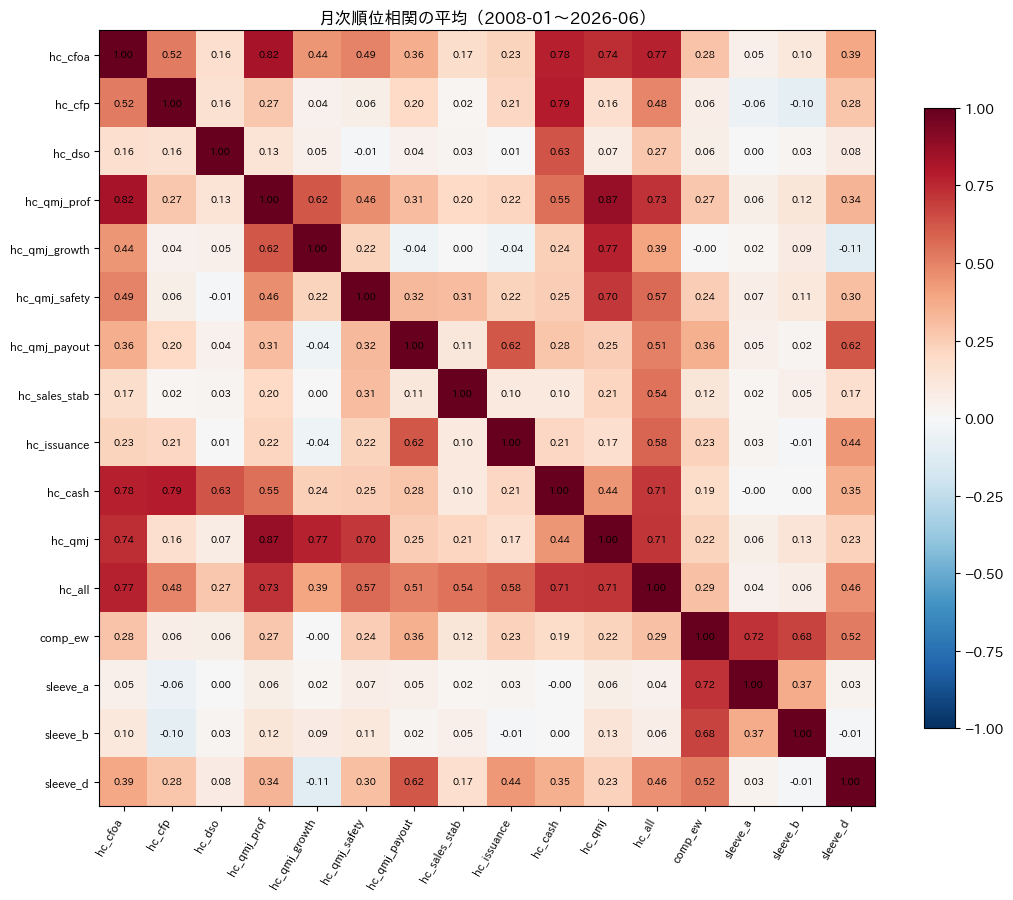

In [4]:
def row_rank_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    m = a.notna() & b.notna()
    ra = a.where(m).rank(axis=1)
    rb = b.where(m).rank(axis=1)
    ra = ra.sub(ra.mean(axis=1), axis=0)
    rb = rb.sub(rb.mean(axis=1), axis=0)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))

names = COMPONENTS + ["hc_sales_stab", "hc_issuance", "hc_cash", "hc_qmj", "hc_all", "comp_ew", "sleeve_a", "sleeve_b", "sleeve_d"]
corr = pd.DataFrame(index=names, columns=names, dtype=float)
for i, a in enumerate(names):
    for b in names[i:]:
        v = 1.0 if a == b else float(row_rank_corr(scores[a], scores[b]).mean())
        corr.loc[a, b] = corr.loc[b, a] = v
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(names)), names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("月次順位相関の平均（2008-01〜2026-06）")
plt.tight_layout()
plt.show()

### スタイルへの傾き

サイズ（log ユニバースウェイト）、`vola60`、`mom12_1`、`bp_act` との順位相関と、BM 加重平均スコア（ロングオンリー・BM 制約下でアクティブに取れるかの目安。`04_style_tilt` の AI スコアは +0.8 だった）。

In [5]:
style = {"log size": np.log(univ.where(univ > 0)), **{c: store.alpha(f"core/{c}", START, END).reindex(index=univ.index, columns=univ.columns) for c in ["vola60", "mom12_1", "bp_act"]}}
bmw = bm.reindex(index=univ.index, columns=univ.columns)
rows = {}
for n in SCORES:
    s = scores[n]
    rows[n] = {**{f"corr({k})": float(row_rank_corr(s, v).mean()) for k, v in style.items()}, "BM 加重平均": float(((s * bmw).sum(axis=1) / bmw.where(s.notna()).sum(axis=1)).mean())}
display(pd.DataFrame(rows).T.round(3))

,corr(log size),corr(vola60),corr(mom12_1),corr(bp_act),BM 加重平均
comp_ew,0.035,-0.154,0.595,-0.224,-0.126
hc_cash,0.048,-0.157,0.009,0.011,0.126
hc_qmj,0.159,-0.408,0.106,-0.440,0.425
hc_sales_stab,0.121,-0.320,0.056,-0.143,0.215
hc_issuance,-0.038,-0.196,-0.009,0.128,-0.051
hc_all,0.091,-0.392,0.058,-0.164,0.270
hc_cfoa,0.117,-0.303,0.103,-0.343,0.272
hc_cfp,-0.005,-0.072,-0.080,0.335,0.076
hc_dso,0.024,0.013,0.031,-0.001,0.020
hc_qmj_prof,0.136,-0.292,0.109,-0.421,0.326


## 3. 一括計算

In [6]:
returns = {kind: store.returns(RISK_MODEL, col, START, 202607) for kind, col in RETURN_KINDS.items()}
schedule = india_tax_schedule(FPI_TYPE)
reports = {}
for n in SCORES:
    reports[n] = compute_alpha_report(n, scores[n], univ, bm, returns, n_quantiles=N_QUANTILES, cw_max_weight=CW_MAX_WEIGHT, tax_schedule=schedule, cost_buy=COST_BUY, cost_sell=COST_SELL, burn_in=BURN_IN, tax_kind="drtn")
    print(f"{n:16s} done")
first = next(iter(reports.values()))
print(f"最上位 = {first.top}。評価期間 {first.series['ew_excess']['drtn'].index.min().date()} 〜 {first.series['ew_excess']['drtn'].index.max().date()}")

comp_ew          done


hc_cash          done


hc_qmj           done


hc_sales_stab    done


hc_issuance      done


...

hc_dso           done


hc_qmj_prof      done


hc_qmj_growth    done


hc_qmj_safety    done


hc_qmj_payout    done
最上位 = Q5。評価期間 2009-02-28 〜 2026-07-31


## 4. 指標表

In [7]:
tbl = summary_table(reports)
print("drtn（配当込みトータルリターン）")
display(tbl["drtn"].round(3))
print("srtn（固有リターン）")
display(tbl["srtn"].round(3))
display(tbl["共通"].round(3))
for kind in ["drtn", "srtn"]:
    print(f"分位別の年率リターン（{kind}、Q5 = 最上位）")
    display(pd.DataFrame({n: rep.quantile_returns[kind].drop(columns="spread").mean() * 12 for n, rep in reports.items()}).T.round(3))

drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.130,1.165,0.176,1.152,0.099,1.104,0.085,0.790,0.065,0.482,6.982
hc_cash,0.065,0.540,0.068,0.691,0.042,0.480,0.037,0.305,0.023,0.268,3.888
hc_qmj,0.032,0.361,0.021,0.109,0.025,0.315,0.018,0.196,0.031,0.172,2.496
hc_sales_stab,0.034,0.370,0.010,0.085,0.021,0.284,0.014,0.155,0.017,0.163,2.361
hc_issuance,0.065,0.519,0.062,0.674,0.044,0.419,0.036,0.297,0.027,0.322,4.669
hc_all,0.074,0.821,0.087,0.584,0.036,0.555,0.046,0.520,0.038,0.282,4.092
hc_cfoa,0.063,0.700,0.068,0.437,0.031,0.440,0.044,0.487,0.032,0.210,3.038
hc_cfp,0.065,0.401,0.054,0.590,0.057,0.406,0.041,0.255,0.014,0.168,2.437
hc_dso,0.037,0.256,0.028,0.324,0.027,0.227,0.013,0.092,0.009,0.122,1.766
hc_qmj_prof,0.048,0.508,0.058,0.355,0.023,0.305,0.031,0.332,0.033,0.207,3.000


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.101,1.009,0.117,1.071,0.063,0.784,0.055,0.563,0.039,0.380,5.501
hc_cash,0.045,0.462,0.037,0.450,0.022,0.307,0.016,0.169,0.011,0.141,2.039
hc_qmj,0.029,0.359,0.007,0.052,0.022,0.367,0.014,0.175,0.023,0.192,2.777
hc_sales_stab,0.043,0.571,0.006,0.069,0.024,0.389,0.023,0.311,0.011,0.140,2.033
hc_issuance,0.043,0.426,0.037,0.459,0.021,0.245,0.015,0.151,0.017,0.212,3.078
hc_all,0.057,0.691,0.052,0.497,0.026,0.464,0.029,0.362,0.024,0.256,3.713
hc_cfoa,0.047,0.569,0.041,0.391,0.023,0.392,0.028,0.336,0.021,0.199,2.884
hc_cfp,0.040,0.343,0.022,0.261,0.026,0.278,0.016,0.139,0.005,0.057,0.829
hc_dso,0.030,0.263,0.004,0.052,0.018,0.181,0.007,0.057,0.003,0.041,0.596
hc_qmj_prof,0.033,0.395,0.029,0.258,0.016,0.274,0.016,0.196,0.022,0.201,2.910


指標,回転率 EW,回転率 CW,コストドラッグ,税ドラッグ,短期比率
comp_ew,4.022,4.169,0.017,0.028,0.809
hc_cash,1.891,1.815,0.008,0.020,0.801
hc_qmj,1.107,0.797,0.005,0.010,0.424
hc_sales_stab,1.314,1.065,0.005,0.014,0.495
hc_issuance,2.335,2.055,0.010,0.018,0.667
hc_all,1.916,1.511,0.008,0.019,0.639
hc_cfoa,1.086,0.776,0.004,0.014,0.517
hc_cfp,1.546,1.255,0.006,0.017,0.628
hc_dso,2.049,2.014,0.008,0.014,0.844
hc_qmj_prof,1.091,0.789,0.004,0.012,0.478


分位別の年率リターン（drtn、Q5 = 最上位）


,Q1,Q2,Q3,Q4,Q5
comp_ew,0.106,0.146,0.180,0.217,0.282
hc_cash,0.149,0.171,0.191,0.202,0.217
hc_qmj,0.163,0.193,0.193,0.198,0.185
hc_sales_stab,0.176,0.193,0.186,0.171,0.186
hc_issuance,0.154,0.168,0.177,0.222,0.217
hc_all,0.139,0.185,0.197,0.190,0.226
hc_cfoa,0.148,0.184,0.193,0.191,0.215
hc_cfp,0.163,0.154,0.193,0.205,0.217
hc_dso,0.161,0.182,0.189,0.214,0.189
hc_qmj_prof,0.142,0.184,0.203,0.202,0.200


分位別の年率リターン（srtn、Q5 = 最上位）


,Q1,Q2,Q3,Q4,Q5
comp_ew,-0.039,-0.018,0.004,0.032,0.078
hc_cash,-0.014,0.012,0.022,0.013,0.023
hc_qmj,-0.000,0.013,0.017,0.021,0.007
hc_sales_stab,0.016,0.024,0.016,0.008,0.021
hc_issuance,-0.016,-0.004,0.018,0.044,0.021
hc_all,-0.017,0.011,0.017,0.015,0.035
hc_cfoa,-0.017,0.012,0.021,0.016,0.025
hc_cfp,-0.005,-0.002,0.023,0.025,0.017
hc_dso,0.003,0.017,0.019,0.040,0.008
hc_qmj_prof,-0.018,0.013,0.021,0.030,0.011


## 5. 累積図

### 柱スコアと comp_ew

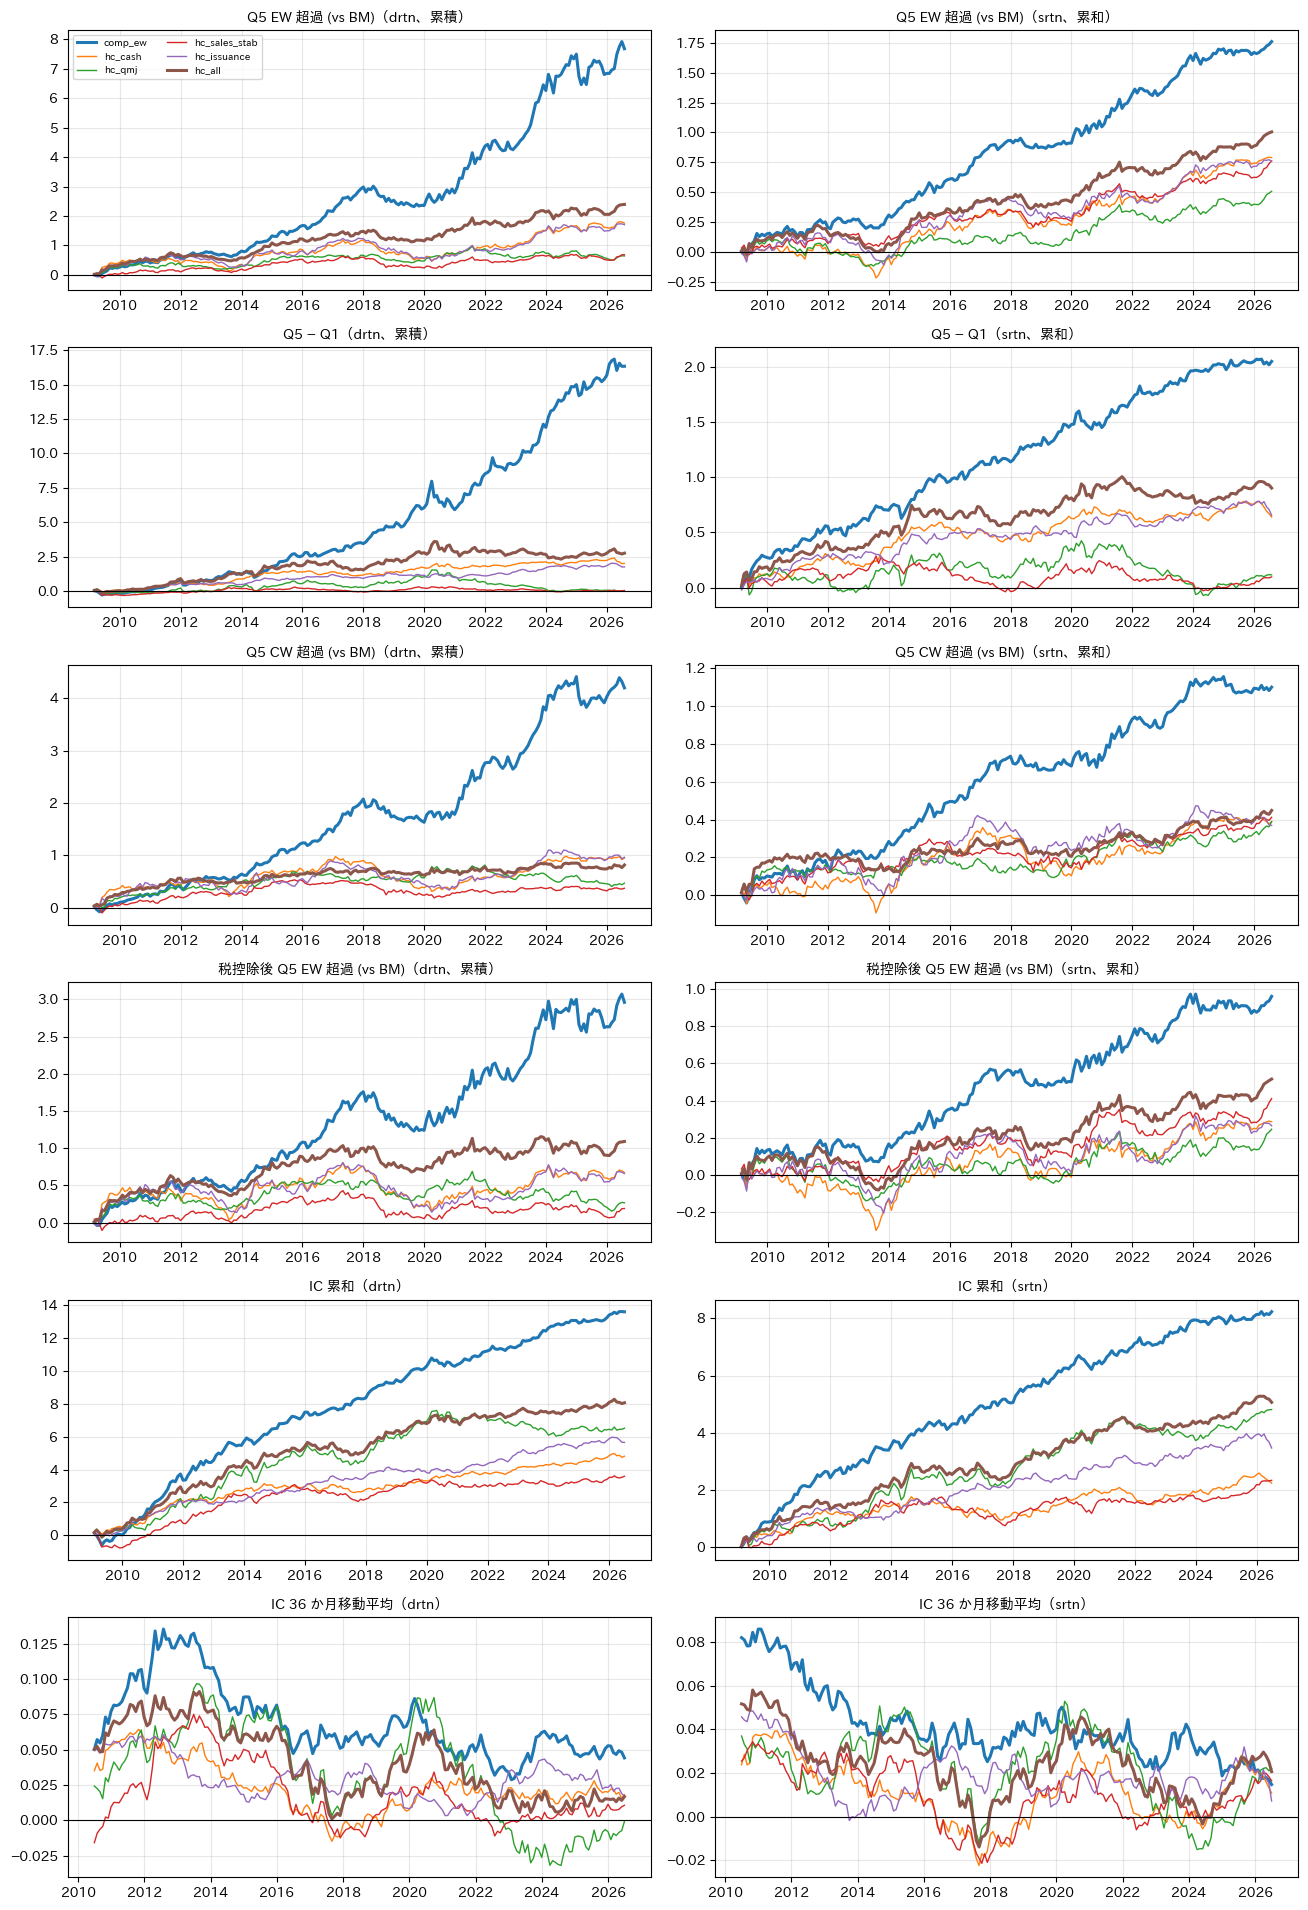

In [8]:
fig = plot_cumulative({n: reports[n] for n in ["comp_ew"] + PILLARS}, highlight=["comp_ew", "hc_all"])
plt.show()

### 構成スコア

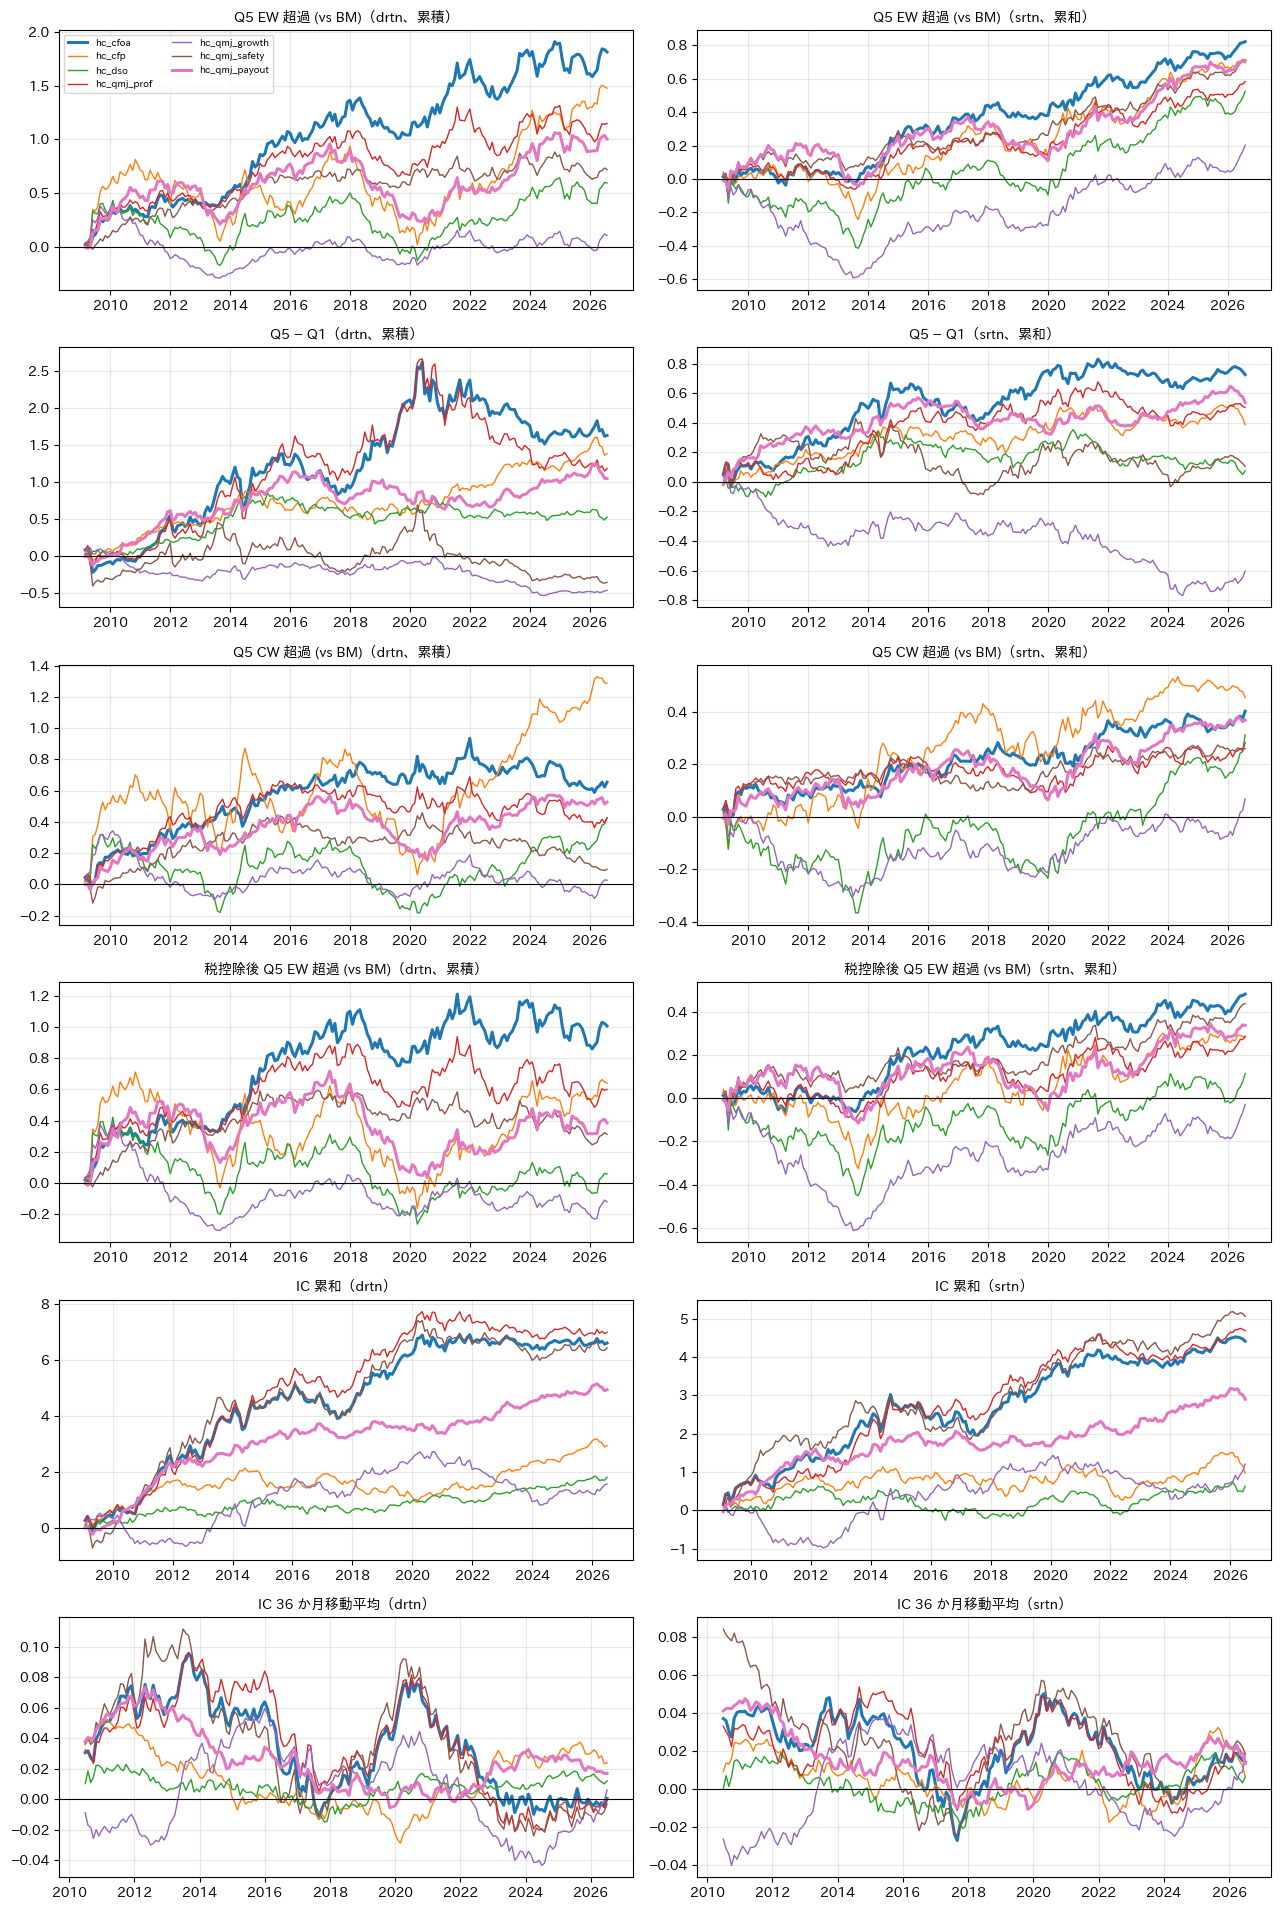

In [9]:
fig = plot_cumulative({n: reports[n] for n in COMPONENTS}, highlight=["hc_cfoa", "hc_qmj_payout"])
plt.show()

## 6. アルファ横断の棒グラフ（年率、IC は平均）

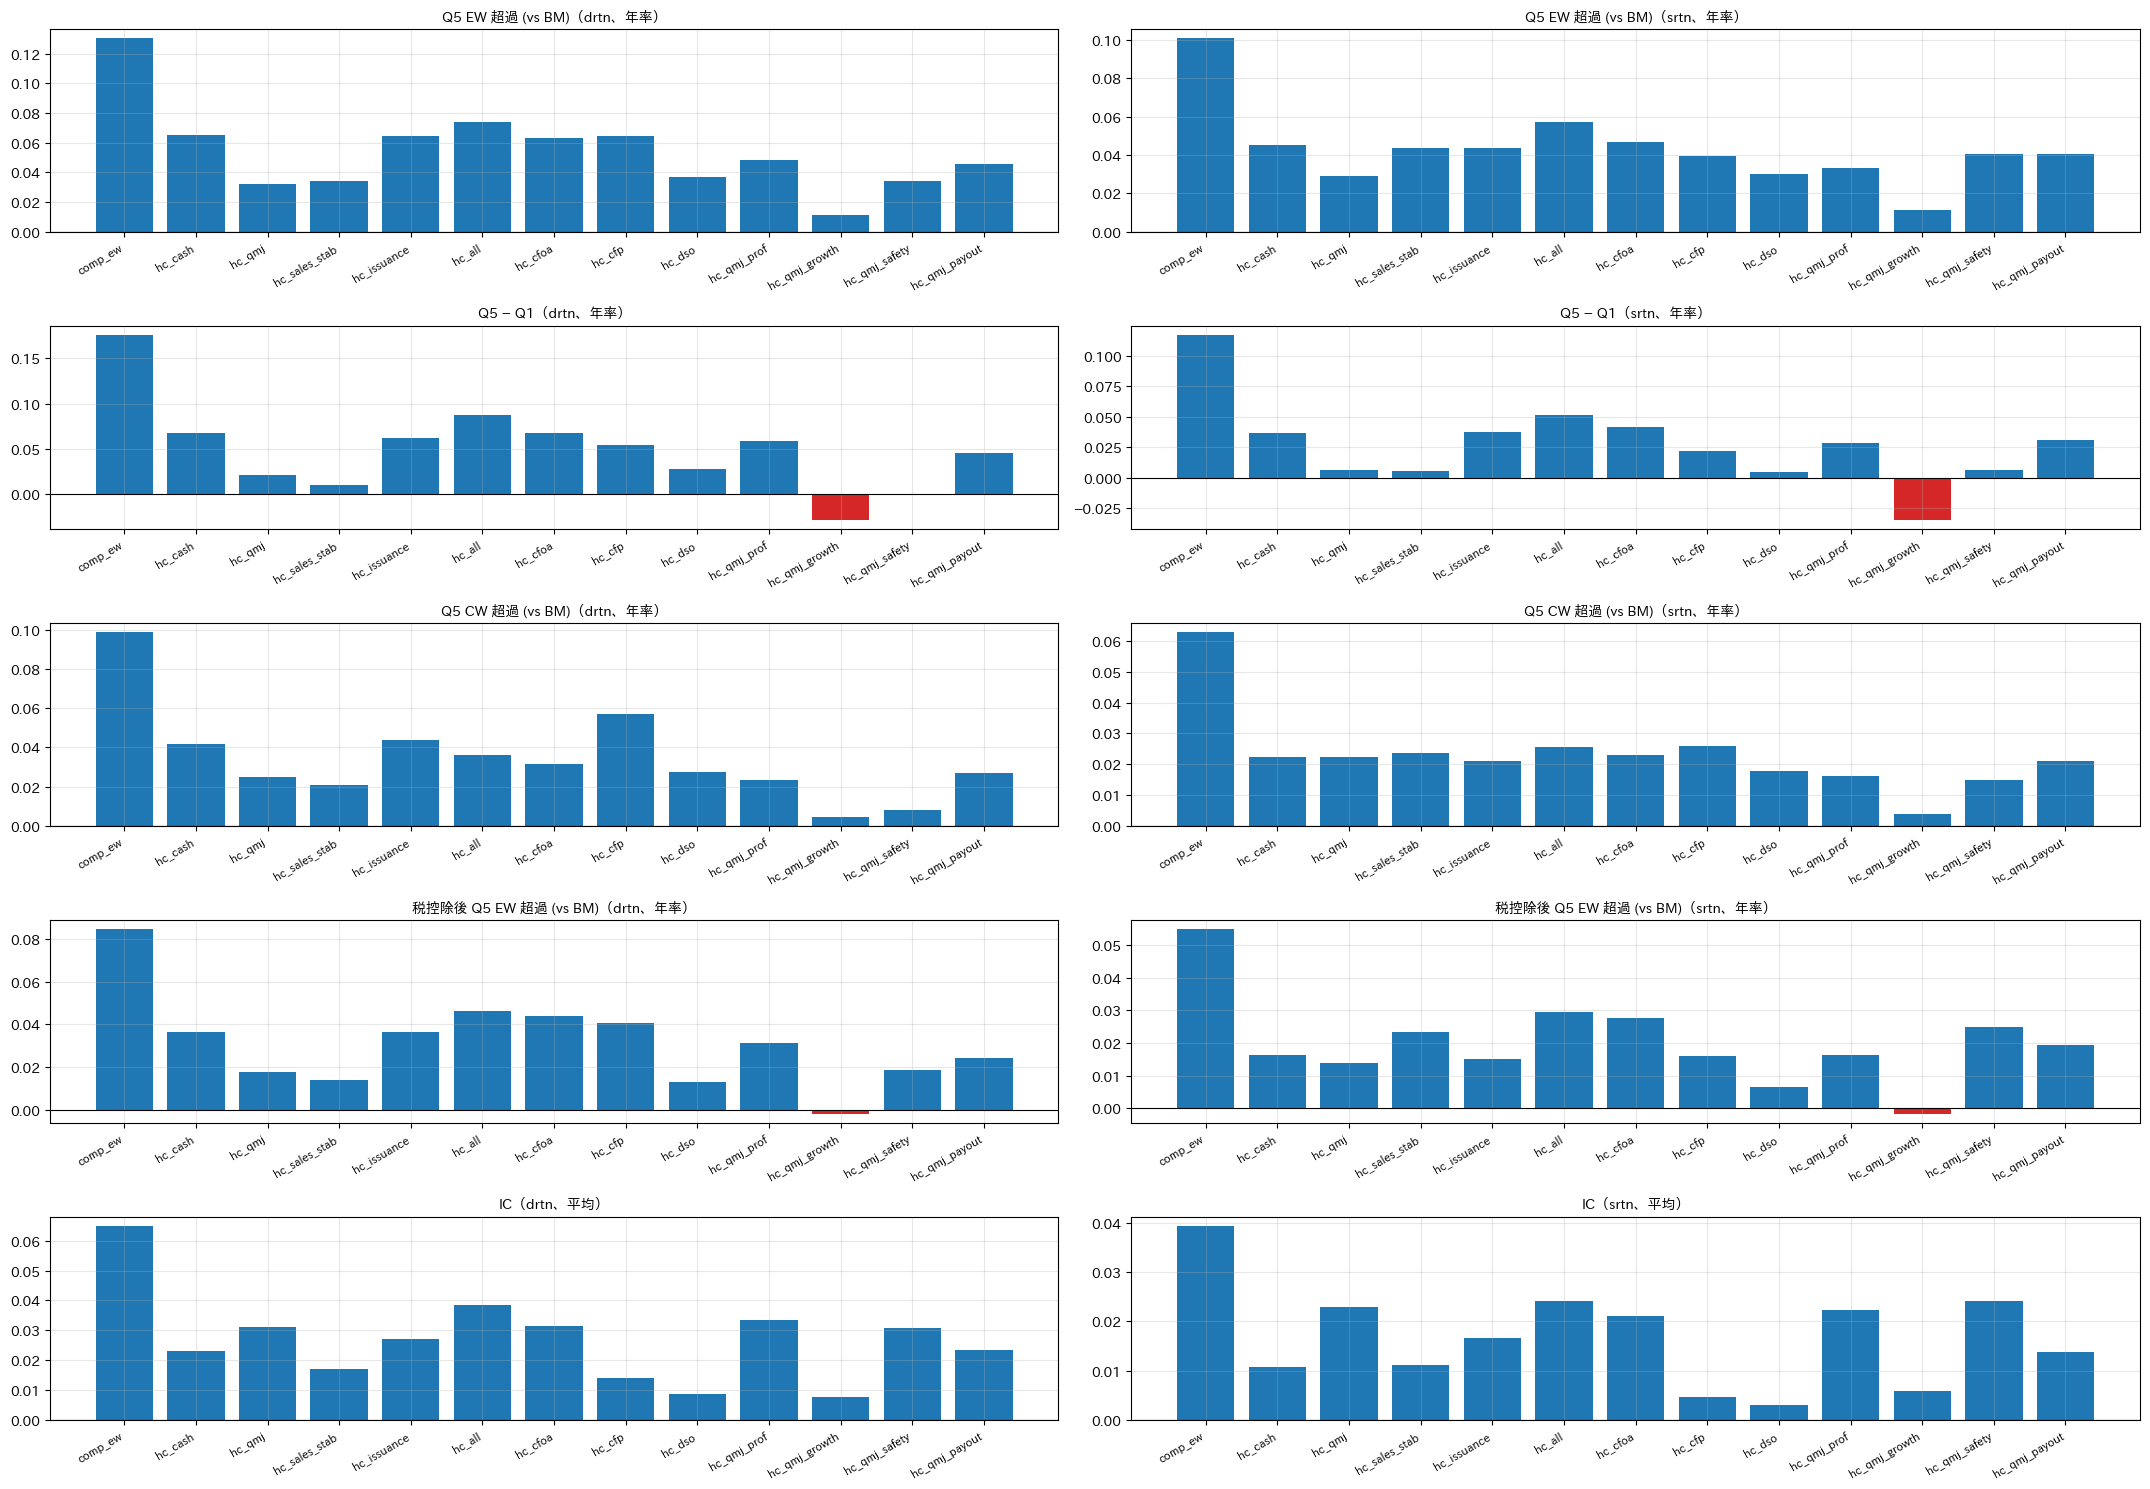

In [10]:
fig = plot_cross_alpha_bars(reports)
plt.show()

## 7. 期間別の安定性

srtn ベースの Q5 EW 超過、Q5 − Q1（年率）と IC 平均。

In [11]:
PERIODS = {"2009–2013": ("2009-01", "2013-12"), "2014–2018": ("2014-01", "2018-12"), "2019–2022": ("2019-01", "2022-12"), "2023–2026": ("2023-01", "2026-07")}
rows = {}
for n, rep in reports.items():
    row = {}
    for p, (a, b) in PERIODS.items():
        row[(p, "Q5 EW 超過")] = rep.series["ew_excess"]["srtn"].loc[a:b].mean() * 12
        row[(p, "Q5−Q1")] = rep.series["spread"]["srtn"].loc[a:b].mean() * 12
        row[(p, "IC")] = rep.series["ic"]["srtn"].loc[a:b].mean()
    rows[n] = row
sub = pd.DataFrame(rows).T
sub.columns = pd.MultiIndex.from_tuples(sub.columns)
display(sub.round(3))

2009–2013               2014–2018               2019–2022               2023–2026              
               Q5 EW 超過  Q5−Q1     IC  Q5 EW 超過  Q5−Q1     IC  Q5 EW 超過  Q5−Q1     IC  Q5 EW 超過  Q5−Q1     IC
comp_ew           0.063  0.143  0.059     0.114  0.117  0.039     0.116  0.123  0.031     0.117  0.075  0.020
hc_cash          -0.010  0.074  0.024     0.059  0.024 -0.003     0.051  0.034  0.012     0.095  0.004  0.010
hc_qmj           -0.008  0.025  0.034     0.024  0.013  0.022     0.040 -0.020  0.014     0.074  0.003  0.019
hc_sales_stab     0.027  0.047  0.027     0.024 -0.041 -0.001     0.053  0.011 -0.000     0.082  0.007  0.018
hc_issuance      -0.005  0.046  0.018     0.072  0.058  0.021     0.030  0.020  0.018     0.086  0.017  0.006
hc_all            0.014  0.095  0.038     0.065  0.042  0.018     0.066  0.040  0.020     0.096  0.019  0.018
hc_cfoa           0.015  0.101  0.039     0.065  0.021  0.013     0.038  0.029  0.017     0.076  0.003  0.011
hc_cfp           -0.016  0.055  0.014     0.059  0.005 -0.006     0.048  0.027  0.005     0.080 -0.004  0.006
hc_dso           -0.049  0.049  0.005     0.041 -0.021 -0.007     0.063  0.007  0.009     0.087 -0.025  0.008
hc_qmj_prof       0.004  0.052  0.037     0.034  0.039  0.021     0.031  0.002  0.012     0.076  0.012  0.015
hc_qmj_growth    -0.108 -0.072  0.002     0.049  0.003  0.016     0.053 -0.050 -0.008     0.077 -0.017  0.013
hc_qmj_safety     0.027  0.061  0.045     0.016 -0.055  0.010     0.048  0.018  0.022     0.085  0.002  0.017
hc_qmj_payout     0.008  0.069  0.025     0.035  0.020  0.005     0.038 -0.009  0.012     0.096  0.038  0.012

## 所見

**データ定義（§0）**: `core` のアクルーアル（`acc_bs`・`acc_cf`）は名前と逆向きで、(営業 CF − 純利益)/総資産と順位相関 0.5〜0.86。
インドの性質別損益計算書では「売上総利益 − 販管費」が営業利益の代わりにならず（IT サービスが最下位に集中）、販管費比率は単独で正の IC（t 3.3）を持つ。
このため CbOP は営業 CF/総資産で代替し、QMJ の −ACC は `acc_bs` をそのままの符号で使った。

**1. 統合スコアは単独で comp_ew の半分程度。**

| | IC（drtn） | IC t | Q5 − Q1 | Q5 CW 超過 | 税後 Q5 EW 超過 | 回転率 |
| --- | --- | --- | --- | --- | --- | --- |
| comp_ew | 0.065 | 7.0 | 17.6% | 9.9% | 8.5% | 402% |
| hc_all | 0.038 | 4.1 | 8.7% | 3.6% | 4.6% | 192% |

**2. 柱別に見ると、効いているのは CFOA と発行・還元だけ。**

- ① キャッシュ収益性: 営業 CF/総資産は IC t 3.0（srtn でも 2.9）。CF/P は drtn の t 2.4 が srtn では 0.8 に落ち、大半はバリューのファクターリターン。
  売掛金回転日数の変化は t 1.8 / 0.6 で、インドの売掛膨張仮説は単独では支持されない。
- ② QMJ: 収益性は t 3.0。安全性は IC が正（t 2.4）でも分位リターンが平坦（Q1 18.8%、Q5 18.6%）で、スプレッドにならない。
  成長（5 年変化）は t 0.9 で効かず、Chan et al. (2003) の「成長に持続性がない」と整合する。
- ③ 売上成長の安定性: IC t 2.4 だが Q5 − Q1 は 1.0% で単調でない。
- ④ 資本規律: 単体で最も強い（IC t 4.7、Q5 − Q1 6.2%）。QMJ 還元も t 4.0。ただし comp_ew のスリーブ D と相関 0.44 / 0.62 で、既に取り込まれている情報が多い。

**3. スタイルの傾き。** QMJ と安全性は低ボラ（`vola60` と −0.41 / −0.63）に強く傾き、BM 加重平均は +0.43 / +0.49。
統合スコアでも +0.27 で、AI スコア（+0.8）ほどではないが最適化の制約で一部吸収される可能性がある。

**4. 回転率と税は提案どおり有利。** 統合スコアの回転率は comp_ew の半分以下、税ドラッグ 1.9%（comp_ew 2.8%）、短期比率 64%（81%）。

**5. 期間別。** 統合スコアの srtn Q5 − Q1 は 4 期間とも正（9.5% → 4.2% → 4.0% → 1.9%）だが減衰している。

→ 採用判断は単独の強さではなく comp_ew への上乗せで行う（`02_incremental_vs_comp_ew`）。